# CSC14120 — LẬP TRÌNH SONG SONG: BÁO CÁO GIỮA KỲ (MIDTERM REPORT)
## Đồ án: Ghép ảnh Panorama tăng tốc bằng CUDA (CUDA-Accelerated Panorama Image Stitching)
> **Nhóm thực hiện:** Nhóm 19 (Group 19)  
> **Kho lưu trữ mã nguồn:** [GitHub Repository (thong7d/Panorama-Stitching)](https://github.com/thong7d/Panorama-Stitching)  
> **Thư mục dữ liệu:** [Google Drive Dataset Folder](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)  

---

### THÀNH VIÊN NHÓM VÀ PHÂN CHIA CÔNG VIỆC (TEAM MEMBERS AND WORKLOAD ALLOCATION)

| STT | Họ và tên | MSSV | Vai trò và nhiệm vụ cụ thể |
|:---:|---|:---:|---|
| 1 | **Phạm Minh Thông** | 23120364 | Kiến trúc tổng thể, Quy trình tiền xử lý/crop 16:9, Giai đoạn 1 và Giai đoạn 5 (RANSAC DLT + kiểm tra hình học/fallback) |
| 2 | **Nguyễn Lê Tấn Tiến** | 23120369 | Thu thập tập ảnh đa địa điểm & Manifest, Giai đoạn 2 (FAST-9 NMS Top-K) & Giai đoạn 3 (Mô tả ORB) |
| 3 | **Đào Quốc Tuấn** | 23120392 | Giai đoạn 4 (Khớp Hamming 8x32-bit), Giai đoạn 6 (Chiếu ngược Bilinear), Bộ kiểm thử Benchmark & Phân tích Amdahl |

### KẾ HOẠCH PHÂN CÔNG CÔNG VIỆC ĐẾN CUỐI KỲ (WORK ALLOCATION THROUGH THE FINAL MILESTONE)

| Phiên bản / Sản phẩm bàn giao | Phạm Minh Thông | Nguyễn Lê Tấn Tiến | Đào Quốc Tuấn |
|---|---|---|---|
| **V0 (Tuần tự C++)** | Kiến trúc, S1, S5, Tích hợp hệ thống | Dataset, S2, S3 | S4, S6, Đo đạc & Phân tích Amdahl |
| **V1 (CUDA cơ bản)** | Hợp đồng bộ nhớ, Kernel S1 & S5 | Kernel S2 & S3 | Kernel S4 & S6, Thu thập số liệu |
| **V2 (Tối ưu hóa 1)** | Tích hợp & Profile ứng viên Shared Memory | Xác thực tính tương đương detector/descriptor | Đo đạc benchmark và kiểm tra truyền dữ liệu |
| **V3 (Tối ưu hóa 2)** | Quality gate độ chính xác & Tích hợp bản phát hành | Ứng viên thu gọn compaction / Constant memory | Ứng viên so khớp/warp & So sánh Nsight Compute |
| **Báo cáo cuối kỳ & Demo** | Trưởng nhóm kỹ thuật, Tính nhất quán báo cáo | Bộ sưu tập dataset và phân tích phương pháp | Toàn bộ benchmark, biểu đồ, video demo |

*Ghi chú:* Tên của V2/V3 được giữ tạm thời cho đến khi có dữ liệu profiling thực tế của V1, nhưng trách nhiệm phân công và xác thực của từng thành viên là cố định. Mọi thành viên đều nắm vững toàn bộ 6 giai đoạn để tham gia vấn đáp cuối kỳ.


---
## 1. HIỂU BÀI TOÁN & KIẾN TRÚC QUY TRÌNH (PROBLEM UNDERSTANDING & PIPELINE ARCHITECTURE)

### 1.1 Mục tiêu (Objective)
Mục tiêu của bài toán là ghép hai ảnh tĩnh có vùng chồng lấn (chụp từ một tâm phối cảnh duy nhất bằng cách xoay camera tại chỗ, độ chồng lấn 30%–50%) thành một ảnh toàn cảnh (Panorama) góc rộng, độ phân giải cao và liền mạch trong hệ tọa độ của ảnh bên trái (Ảnh A).

### 1.2 Quy trình 6 giai đoạn & Luồng dữ liệu (Six-Stage Pipeline & Data-Flow Architecture)

```text
[Ảnh đầu vào A (RGB)]                       [Ảnh đầu vào B (RGB)]
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 1:      │                       │ Giai đoạn 1:      │
│ Tiền xử lý        │ ──> Mức xám Float ───>│ Tiền xử lý        │
│ (Y=0.299R+0.587G) │     (Gaussian 5x5)    │ (Y=0.299R+0.587G) │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 2:      │                       │ Giai đoạn 2:      │
│ Phát hiện đặc trưng│ ──> Top-K Keypoints ─>│ Phát hiện đặc trưng│
│ (FAST-9 + Top-K)  │     (x, y, angle, resp│ (FAST-9 + Top-K)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         ▼                                           ▼
┌───────────────────┐                       ┌───────────────────┐
│ Giai đoạn 3:      │                       │ Giai đoạn 3:      │
│ Trích xuất mô tả  │ ──> 256-bit Descr ───>│ Trích xuất mô tả  │
│ (Oriented BRIEF)  │     (8 x uint32_t)    │ (Oriented BRIEF)  │
└───────────────────┘                       └───────────────────┘
         │                                           │
         └───────────────────┬───────────────────────┘
                             ▼
                  ┌─────────────────────┐
                  │ Giai đoạn 4:        │
                  │ Khớp đặc trưng      │
                  │ (Hamming + Lowe)    │
                  └─────────────────────┘
                             │
                             ▼ Các cặp điểm tương đồng (Matches)
                  ┌─────────────────────┐
                  │ Giai đoạn 5:        │
                  │ Ước lượng biến đổi  │
                  │ (RANSAC H / fallback│
                  └─────────────────────┘
                             │
                             ▼ Ma trận biến đổi H_A_to_B (3x3)
                  ┌─────────────────────┐
                  │ Giai đoạn 6:        │ <─── [Ảnh gốc RGB A & B]
                  │ Chiếu hình & Trộn   │
                  │ (Bilinear + Feather)│
                  └─────────────────────┘
                             │
                             ▼
                 [Ảnh toàn cảnh Panorama]
```

### 1.3 Tham số bất biến & Hợp đồng chất lượng (Invariant Parameters & Quality Contracts)
Theo **Kế hoạch dự án Plan v4 Mục 3**, các tham số và quy ước toán học sau đây được khóa cố định trên mọi phiên bản (từ V0 CPU tuần tự cho tới V1, V2, V3 CUDA GPU) để đảm bảo so sánh tăng tốc công bằng và có giá trị học thuật:

| Giai đoạn | Thuật toán / Phương pháp | Hợp đồng bất biến & Tham số khóa |
|---|---|---|
| **Giai đoạn 1** | Tiền xử lý (Preprocessing) | Mức xám chuẩn $Y = 0.299R + 0.587G + 0.114B$; Lọc nhiễu Gaussian 5×5 ($\sigma=1.0$), giới hạn biên boundary clamping. |
| **Giai đoạn 2** | FAST-9 + NMS + Top-K | Ngưỡng góc FAST-9 $T=20$ trên đường tròn Bresenham 16 điểm; Non-Maximum Suppression 3×3; Tối đa $K=2000$ keypoints; Sắp xếp tất định: `(response GIẢM DẦN, linear_index TĂNG DẦN)`. |
| **Giai đoạn 3** | Oriented BRIEF / ORB | Kích thước patch $31\times 31$, góc định hướng từ Trọng tâm cường độ (Intensity Centroid) $[-\pi, \pi]$; Bảng 256 cặp kiểm tra chuẩn từ OpenCV `bit_pattern_31_`; Loại bỏ biên an toàn ($R < 20$ px). |
| **Giai đoạn 4** | So khớp vét cạn Hamming | Descriptor 256-bit lưu dưới dạng 8 từ $\times$ 32-bit (`uint32_t words[8]`), tính khoảng cách bit bằng popcount; Kiểm định tỷ số Lowe (Lowe's Ratio Test): $\text{dist}_1 < 0.75 \times \text{dist}_2$. |
| **Giai đoạn 5** | RANSAC Homography + fallback tịnh tiến | 2000 giả thuyết; DLT 4 điểm chuẩn hóa Hartley; ngưỡng chiếu lại $3.0$ px; LCG seed 42. H được kiểm tra diện tích, pole và kích thước canvas; nếu suy biến thì dùng RANSAC tịnh tiến + median trên displacement đồng thuận. |
| **Giai đoạn 6** | Chiếu ngược & Trộn mềm | Ánh xạ tọa độ ngược qua $H_{A\to B}$; Lấy mẫu nội suy song tuyến (Bilinear sampling); Trọng số làm mượt đối xứng (Symmetric feathering) theo khoảng cách tới cả 4 biên để triệt tiêu vết nối. |

### 1.4 Biện luận chất lượng cho các phương pháp đã chọn (Quality Rationale)

| Giai đoạn | Lý do lựa chọn thuật toán đảm bảo chất lượng đầu ra |
|---|---|
| **S1** | Công thức độ chói bảo toàn độ tương phản cấu trúc; Lọc Gaussian giảm nhiễu hạt gây ra các điểm FAST giả mạo mà không làm thay đổi hệ tọa độ hình học. |
| **S2** | FAST-9 mang lại các điểm góc có tính lặp lại rất cao trên các cạnh; NMS loại bỏ các cụm điểm phát hiện dư thừa và Top-K tất định giữ lại các bằng chứng hình học mạnh nhất. |
| **S3** | Góc định hướng từ trọng tâm cường độ giúp BRIEF chống chịu được phép xoay camera, trong khi descriptor 256-bit đủ gọn nhẹ để thực hiện so khớp vét cạn toàn diện. |
| **S4** | Khoảng cách Hamming tính chính xác độ sai biệt bit; Kiểm định tỷ số của Lowe loại bỏ triệt để các cặp ghép nhập nhằng do vân bề mặt lặp lại (repetitive textures). |
| **S5** | RANSAC loại ngoại lai; chuẩn hóa Hartley và refit cải thiện độ ổn định. Kiểm tra hình học ngăn H suy biến từ texture lặp; fallback tịnh tiến là mô hình hạn chế, tất định và phù hợp các cặp panorama quay ngang khi mục tiêu là đầu ra ổn định. |
| **S6** | Ánh xạ ngược (Inverse mapping) ngăn chặn hiện tượng tạo lỗ thủng điểm ảnh; Nội suy song tuyến giảm răng cưa; Trộn mềm đối xứng xóa nhòa đường biên ghép nối. |

### 1.5 Biện luận tính phù hợp với GPU (GPU Suitability Rationale)
1. **Giai đoạn 1:** Tính toán độc lập trên từng điểm ảnh (Embarrassingly parallel). Mỗi thread xử lý 1 pixel. Truy xuất bộ nhớ có tính cục bộ không gian cao (rất lý tưởng để tối ưu Shared Memory Tiling trong V2).
2. **Giai đoạn 2:** Phép kiểm tra đường tròn FAST chỉ sử dụng các phép so sánh số học đơn giản. Bước sắp xếp Top-K sử dụng `thrust::sort_by_key` (Radix Sort song song) để giải quyết giới hạn bộ nhớ của Bitonic Sort khi lên ảnh 4K.
3. **Giai đoạn 3:** Phép xoay patch độc lập cho từng keypoint. Bảng 256 cặp tọa độ mẫu có thể nạp vào bộ nhớ hằng (`__constant__` memory) để tận dụng cơ chế đọc broadcast tốc độ cao của GPU.
4. **Giai đoạn 4:** So khớp vét cạn khoảng cách Hamming được tính toán trực tiếp qua chỉ thị phần cứng `__popc` của CUDA, cho thông lượng tính toán cực cao và đọc bộ nhớ gộp (coalesced memory reads).
5. **Giai đoạn 5:** Đánh giá giả thuyết song song trên quy mô lớn: mỗi CUDA warp hoặc block đánh giá một mô hình ứng viên độc lập cùng một lúc.
6. **Giai đoạn 6:** Ánh xạ ngược tính toán từng pixel trên canvas hoàn toàn độc lập, có thể tận dụng phần cứng Texture Units hoặc bộ đệm Bilinear cache của GPU.


---
## 2. THIẾT LẬP MÔI TRƯỜNG & KIỂM TRA PHẦN CỨNG (ENVIRONMENT SETUP & HARDWARE VERIFICATION)


In [1]:
# 2.1 Thiết lập mã nguồn với 3 lựa chọn linh hoạt (Ưu tiên thư mục giải nén -> File zip sẵn có -> Bấm nút tải lên)
import hashlib
import os
import sys
import zipfile
from pathlib import Path

def source_tree_present(root=Path(".")):
    return (root / "src" / "common.h").is_file() and (root / "src" / "v0_sequential.cpp").is_file()

# LỰA CHỌN 1: Người dùng đã tải lên thư mục giải nén (src/ đã có sẵn tại thư mục hiện tại)
if source_tree_present():
    print("[LỰA CHỌN 1] Đã phát hiện thư mục mã nguồn src/ giải nén sẵn trong session. Sử dụng trực tiếp.")

else:
    # LỰA CHỌN 2: Người dùng đã tải sẵn file .zip vào session trước đó (ví dụ kéo thả vào tab Files của Colab)
    zip_candidates = list(Path(".").glob("*.zip"))
    if "google.colab" in sys.modules:
        zip_candidates += list(Path("/content").glob("*.zip"))

    valid_zips = []
    for zp in zip_candidates:
        try:
            with zipfile.ZipFile(zp) as archive:
                namelist = archive.namelist()
                if any("src/common.h" in name for name in namelist):
                    valid_zips.append(zp)
        except Exception:
            pass

    if valid_zips:
        chosen_zip = valid_zips[0]
        print(f"[LỰA CHỌN 2] Tìm thấy file zip mã nguồn có sẵn trong session: {chosen_zip.name}. Đang tự động giải nén...")
        target = Path("/content/group19_midterm_submission") if "google.colab" in sys.modules else Path(".")
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(chosen_zip) as archive:
            archive.extractall(target)
        if (target / "src").is_dir():
            os.chdir(target)

    # LỰA CHỌN 3: Chưa có src/ và chưa có file zip -> Hiện hộp thoại 'Chọn tệp' (files.upload()) như cũ
    else:
        if "google.colab" not in sys.modules:
            raise FileNotFoundError("Không tìm thấy src/ hoặc file .zip. Hãy giải nén src/ hoặc đặt file Group19_Midterm.zip vào thư mục làm việc.")
        from google.colab import files
        print("[LỰA CHỌN 3] Chưa tìm thấy mã nguồn trong session. Vui lòng bấm nút 'Chọn tệp' (Choose Files) để tải lên file .zip...")
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_names:
            raise FileNotFoundError("Không có file .zip nào được tải lên.")
        target = Path("/content/group19_midterm_submission")
        target.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_names[0]) as archive:
            archive.extractall(target)
        os.chdir(target)

if not source_tree_present():
    raise FileNotFoundError("Không thể tìm thấy mã nguồn src/ sau khi thực hiện các lựa chọn.")

source_hash = hashlib.sha256()
for path in sorted(Path("src").glob("*")):
    if path.is_file():
        source_hash.update(path.name.encode())
        source_hash.update(path.read_bytes())
print(f"[OK] Đang sử dụng cây mã nguồn tại: {Path.cwd()}")
print(f"[OK] Mã băm SHA-256 tổng hợp của src/: {source_hash.hexdigest()}")


[LỰA CHỌN 3] Chưa tìm thấy mã nguồn trong session. Vui lòng bấm nút 'Chọn tệp' (Choose Files) để tải lên file .zip...


Saving Group19_Midterm.zip to Group19_Midterm.zip
[OK] Đang sử dụng cây mã nguồn tại: /content/group19_midterm_submission
[OK] Mã băm SHA-256 tổng hợp của src/: efe586c8167b6e13c43cf8bf8eefdb852258ae4027df7db933f3648f713c9ad3


In [2]:
# 2.2 Xác thực phần cứng thực thi thực tế và trình biên dịch C++
import glob
import platform
import shutil
import subprocess

def run_checked(command):
    completed = subprocess.run(command, text=True, capture_output=True)
    if completed.stdout:
        print(completed.stdout, end="")
    if completed.stderr:
        print(completed.stderr, end="", file=sys.stderr)
    completed.check_returncode()
    return completed

print(f"Hệ điều hành: {platform.platform()}")
print(f"Bộ vi xử lý CPU: {platform.processor() or 'Báo cáo bởi hệ điều hành'}")
print(f"Số nhân CPU logic: {os.cpu_count()}")

if shutil.which("nvidia-smi"):
    print("[Thiết bị CUDA khả dụng]")
    run_checked(["nvidia-smi"])
else:
    print("[Môi trường chỉ có CPU: Hợp lệ cho phiên bản tuần tự V0 giữa kỳ]")

CXX = shutil.which("g++") or shutil.which("clang++")
if CXX is None and os.name == "nt":
    candidates = glob.glob(
        str(Path(os.environ.get("LOCALAPPDATA", "")) /
            "Microsoft/WinGet/Packages/**/mingw64/bin/g++.exe"),
        recursive=True,
    )
    CXX = candidates[0] if candidates else None
if CXX is None:
    raise RuntimeError("Cần có trình biên dịch C++17 (g++ hoặc clang++).")
print(f"Trình biên dịch C++: {CXX}")
run_checked([CXX, "--version"])


Hệ điều hành: Linux-6.6.122+-x86_64-with-glibc2.39
Bộ vi xử lý CPU: x86_64
Số nhân CPU logic: 2
[Thiết bị CUDA khả dụng]
Sun Oct 25 10:45:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                  

CompletedProcess(args=['/usr/bin/g++', '--version'], returncode=0, stdout='g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0\nCopyright (C) 2023 Free Software Foundation, Inc.\nThis is free software; see the source for copying conditions.  There is NO\nwarranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.\n\n', stderr='')

In [3]:
# 2.3 Cài đặt các thư viện Python đo đạc và xác thực
import importlib.util
packages = {
    "PIL": "pillow",
    "pillow_heif": "pillow-heif",
    "numpy": "numpy",
    "cv2": "opencv-python-headless",
    "matplotlib": "matplotlib",
    "nbformat": "nbformat",
}
missing_packages = [
    package for module, package in packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    run_checked([sys.executable, "-m", "pip", "install", "-q", *missing_packages])
print(f"[OK] Các thư viện phụ thuộc Python đã sẵn sàng; đã cài thêm: {missing_packages or 'không có'}")


[OK] Các thư viện phụ thuộc Python đã sẵn sàng; đã cài thêm: ['pillow-heif']


In [4]:
# 2.4 Xác thực cấu trúc thư mục và các tệp mã nguồn C++ bắt buộc
import os
import sys

required_paths = [
    "src/common.h", "src/cuda_utils.cuh", "src/versions.h",
    "src/main.cu", "src/v0_sequential.cpp", "Makefile",
    "THIRD_PARTY_NOTICES.md"
]

missing = [p for p in required_paths if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"Thiếu các tệp mã nguồn dự án bắt buộc: {missing}")

print(f"[OK] Đã xác thực các file mã nguồn và biên dịch bắt buộc tại: {os.getcwd()}.")


[OK] Đã xác thực các file mã nguồn và biên dịch bắt buộc tại: /content/group19_midterm_submission.


---
## 3. TẬP DỮ LIỆU THỰC NGHIỆM & TIỀN XỬ LÝ (CHUẨN HÓA 16:9)
Đồ án sử dụng 4 cặp ảnh chụp thực tế trong các môi trường đa dạng, cùng 1 cặp ảnh tổng hợp có Ground-truth chuẩn:
- **Tỷ lệ khung hình:** Chuẩn 16:9 (Cắt trọng tâm Center-cropped).
- **Ba độ phân giải tiêu chuẩn:**
  - **Small (Nhỏ):** $1280 \times 720$ (720p — 0.92 MP)
  - **Medium (Vừa):** $1920 \times 1080$ (1080p — 2.07 MP)
  - **Large (Lớn):** $3840 \times 2160$ (4K UHD — 8.29 MP)
- **Thư mục lưu trữ dữ liệu Google Drive:** [Truy cập toàn bộ ảnh gốc và dữ liệu tiền xử lý trên Google Drive](https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link)

| Cặp ảnh | Bối cảnh chụp thực tế | Độ chồng lấn ước lượng | Ý nghĩa thực nghiệm |
|---|---|---:|---|
| **Site 1** | Bếp/phòng tiện ích trong nhà | 38% | Thị sai cận cảnh, bất liên tục độ sâu, phơi sáng trong nhà |
| **Site 2** | Mái nhà đô thị, mái ngói và đường chân trời | 33% | Bầu trời ít vân, mái ngói lặp, đặc trưng ở xa |
| **Site 3** | Hành lang kỹ thuật trên sân thượng có lưới an toàn | 49% sau crop | Lưới lặp, phối cảnh sâu, nền trời sáng |
| **Challenging** | Bếp/phòng làm việc cận cảnh trong nhà | 39% | Thị sai, che khuất cục bộ, nhiều mặt phẳng độ sâu |

*Cách ước lượng overlap:* Site 1, Site 2 và Challenging dùng displacement ngang robust của các match đồng thuận. Site 3 ban đầu được ước lượng khoảng 51.87%; bước tiền xử lý bỏ 2% mép giao nhau ở mỗi ảnh để đưa về khoảng 49% mà không sửa ảnh gốc. Đây là số liệu mô tả dataset; độ chính xác synthetic được đánh giá riêng bằng ground-truth.


In [5]:
# 3.1 Cung cấp dataset: Hỗ trợ Google Drive Mount, tệp zip có sẵn, hoặc tải lên thủ công
import json
import os
import shutil
import sys
import zipfile
from pathlib import Path
from PIL import Image

manifest_path = Path("dataset/manifest.json")

def check_raw_images_exist():
    expected_raw = [
        Path("dataset/site1_indoor/in1.jpg"),
        Path("dataset/site1_indoor/in2.jpg"),
        Path("dataset/site2_outdoor/out1.jpg"),
        Path("dataset/site2_outdoor/out2.jpg"),
        Path("dataset/site3_custom/cus1.jpg"),
        Path("dataset/site3_custom/cus2.jpg"),
        Path("dataset/challenging/cha1.jpg"),
        Path("dataset/challenging/cha2.jpg"),
    ]
    return all(p.is_file() for p in expected_raw)

need_dataset = not check_raw_images_exist()

if need_dataset and "google.colab" in sys.modules:
    print("[DATASET] Đang tìm kiếm tập ảnh thô trong môi trường...")
    # Lựa chọn 1: Tìm kiếm trong Google Drive đã mount (/content/drive/MyDrive)
    drive_root = Path("/content/drive/MyDrive")
    if drive_root.is_dir():
        print("[TÌM KIẾM DRIVE] Đã phát hiện Google Drive được mount. Đang tìm kiếm dataset...")
        for candidate in drive_root.glob("**/*"):
            if candidate.is_file() and candidate.name.lower().endswith(".zip") and "midterm" not in candidate.name.lower():
                try:
                    with zipfile.ZipFile(candidate) as archive:
                        namelist = archive.namelist()
                        if any("site1_indoor" in n or "in1.jpg" in n.lower() for n in namelist):
                            print(f"[GOOGLE DRIVE] Tìm thấy tệp zip dataset: {candidate.name}. Đang tự động giải nén...")
                            archive.extractall(Path.cwd())
                            break
                except Exception:
                    pass
            elif candidate.is_dir() and ((candidate / "site1_indoor").is_dir() or (candidate / "dataset" / "site1_indoor").is_dir()):
                print(f"[GOOGLE DRIVE] Tìm thấy thư mục dataset trong Drive: {candidate}. Đang sao chép...")
                source_dir = candidate if (candidate / "site1_indoor").is_dir() else (candidate / "dataset")
                Path("dataset").mkdir(parents=True, exist_ok=True)
                for item in source_dir.iterdir():
                    dest = Path("dataset") / item.name
                    if item.is_dir():
                        shutil.copytree(item, dest, dirs_exist_ok=True)
                    else:
                        shutil.copy2(item, dest)
                break

    # Lựa chọn 2: Tìm tệp zip dataset có sẵn trong /content hoặc thư mục hiện tại
    if not check_raw_images_exist():
        local_zips = [p for p in Path("/content").glob("*.zip") if "midterm" not in p.name.lower()] + [p for p in Path(".").glob("*.zip") if "midterm" not in p.name.lower()]
        for lz in local_zips:
            try:
                with zipfile.ZipFile(lz) as archive:
                    namelist = archive.namelist()
                    if any("site1_indoor" in n or "in1.jpg" in n.lower() for n in namelist):
                        print(f"[TỰ ĐỘNG] Tìm thấy tệp zip dataset tại: {lz.name}. Đang giải nén...")
                        archive.extractall(Path.cwd())
                        break
            except Exception:
                pass

    # Lựa chọn 3: Nếu vẫn chưa có ảnh -> Hiện hộp thoại tải tệp zip lên như cũ
    if not check_raw_images_exist():
        from google.colab import files
        print("[HÀNH ĐỘNG] Chưa tìm thấy ảnh gốc trong Drive hoặc session. Vui lòng tải lên tệp zip chứa dataset:")
        uploaded = files.upload()
        dataset_archives = [name for name in uploaded if name.lower().endswith(".zip")]
        if dataset_archives:
            with zipfile.ZipFile(dataset_archives[0]) as archive:
                archive.extractall(Path.cwd())

# Đảm bảo dataset/manifest.json luôn tồn tại và đầy đủ thông tin chuẩn (bao gồm capture_location)
if not manifest_path.is_file():
    Path("dataset").mkdir(parents=True, exist_ok=True)
    default_manifest = {
        "project": "CSC14120 - Panorama Image Stitching",
        "aspect_ratio": "16:9",
        "resolutions": {"small": [1280, 720], "medium": [1920, 1080], "large": [3840, 2160]},
        "drive_url": "https://drive.google.com/drive/folders/1vnD51fqHjY-HGqp365dTa1SX_0femIwG?usp=drive_link",
        "capture_location_note": "Exact GPS coordinates were not recorded; locations are documented by the visible scene context in the original captures.",
        "pairs": [
            {
                "id": "site1_indoor",
                "kind": "standard",
                "directory": "dataset/site1_indoor",
                "left_raw": "in1.jpg",
                "right_raw": "in2.jpg",
                "description": "Group-captured indoor kitchen/utility-room panorama spanning a storage cabinet, doorway, work table and refrigerator",
                "capture_location": "Indoor residential kitchen/utility room (exact GPS not recorded)",
                "estimated_overlap_percent": 38,
                "visual_challenges": ["near-field parallax", "depth discontinuities", "indoor exposure variation"]
            },
            {
                "id": "site2_outdoor",
                "kind": "standard",
                "directory": "dataset/site2_outdoor",
                "left_raw": "out1.jpg",
                "right_raw": "out2.jpg",
                "description": "Group-captured urban rooftop panorama with tiled roofs, distant towers and a bright cloudy sky",
                "capture_location": "Urban rooftop/terrace overlooking residential buildings (exact GPS not recorded)",
                "estimated_overlap_percent": 33,
                "visual_challenges": ["large low-texture sky", "repetitive roof tiles", "distant features"]
            },
            {
                "id": "site3_custom",
                "kind": "standard",
                "directory": "dataset/site3_custom",
                "left_raw": "cus1.jpg",
                "right_raw": "cus2.jpg",
                "description": "Group-captured rooftop corridor panorama with building facades, utility boxes and a repetitive green safety mesh",
                "capture_location": "Outdoor residential rooftop/service corridor (exact GPS not recorded)",
                "estimated_overlap_percent": 49,
                "overlap_crop_fraction": 0.02,
                "visual_challenges": ["repetitive mesh texture", "strong perspective", "depth variation", "bright sky"]
            },
            {
                "id": "challenging",
                "kind": "challenging",
                "directory": "dataset/challenging",
                "left_raw": "cha1.jpg",
                "right_raw": "cha2.jpg",
                "description": "Group-captured close-range indoor panorama spanning a utility table, refrigerator, cooking area and laptop desk",
                "capture_location": "Indoor residential kitchen/utility room (exact GPS not recorded)",
                "estimated_overlap_percent": 39,
                "visual_challenges": ["near-field parallax", "depth discontinuities", "partial occlusion", "indoor exposure variation"]
            },
            {
                "id": "provided",
                "kind": "provided",
                "directory": "dataset/provided",
                "status": "external_blocker",
                "note": "Awaiting official dataset release from course instructors"
            }
        ]
    }
    manifest_path.write_text(json.dumps(default_manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print("[KHỞI TẠO] Đã tự động tạo dataset/manifest.json chuẩn mẫu.")

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
# Đảm bảo capture_location có mặt nếu file manifest cũ bị ghi đè
manifest_updated = False
for pair in manifest.get("pairs", []):
    if pair.get("kind") in {"standard", "challenging"} and not pair.get("capture_location"):
        pair["capture_location"] = f"{pair['id']} recorded scene context"
        manifest_updated = True
if manifest_updated:
    manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

real_pairs = [p for p in manifest["pairs"] if p.get("kind") in {"standard", "challenging"}]
raw_missing = [
    Path(p["directory"]) / name
    for p in real_pairs for name in (p["left_raw"], p["right_raw"])
    if not (Path(p["directory"]) / name).is_file()
]
if raw_missing:
    raise FileNotFoundError(f"Còn thiếu các tệp ảnh gốc: {raw_missing}")

expected = {"small": (1280, 720), "medium": (1920, 1080), "large": (3840, 2160)}
prepared = [
    Path(p["directory"]) / f"{side}_{resolution}.jpg"
    for p in real_pairs for side in ("left", "right") for resolution in expected
]
if not all(path.is_file() for path in prepared):
    print("[TIỀN XỬ LÝ] Tiến hành tiền xử lý và cắt chuẩn 16:9 cho toàn bộ dataset...")
    run_checked([sys.executable, "scripts/preprocess_dataset.py"])
for path in prepared:
    resolution = path.stem.rsplit("_", 1)[-1]
    with Image.open(path) as image:
        assert image.size == expected[resolution], (path, image.size)
print(f"[OK] Đã xác thực thành công {len(prepared)} ảnh thực tế đã chuẩn hóa trên 4 cặp và 3 độ phân giải.")


[DATASET] Đang tìm kiếm tập ảnh thô trong môi trường...
[HÀNH ĐỘNG] Chưa tìm thấy ảnh gốc trong Drive hoặc session. Vui lòng tải lên tệp zip chứa dataset:


Saving dataset-20261025T104635Z-1-001.zip to dataset-20261025T104635Z-1-001.zip
[OK] Đã xác thực thành công 24 ảnh thực tế đã chuẩn hóa trên 4 cặp và 3 độ phân giải.


In [6]:
# 3.2 Sinh và xác thực dữ liệu Ground-truth tổng hợp ở cả 3 độ phân giải
synthetic_files = [
    Path("dataset/synthetic") / f"{side}_{resolution}.jpg"
    for side in ("left", "right") for resolution in ("small", "medium", "large")
]
if not all(path.is_file() for path in synthetic_files):
    run_checked([sys.executable, "scripts/generate_synthetic_test.py"])
ground_truth = json.loads(Path("dataset/synthetic/ground_truth.json").read_text())
assert set(ground_truth) == {"small", "medium", "large"}
print("[OK] Ảnh tổng hợp nhân tạo và ma trận Ground-truth chuẩn xác đã sẵn sàng.")


[OK] Ảnh tổng hợp nhân tạo và ma trận Ground-truth chuẩn xác đã sẵn sàng.


---
## 4. BIÊN DỊCH BẢN TUẦN TỰ V0 (V0 COMPILATION & VERIFICATION)
Biên dịch mã nguồn V0 tuần tự (C++) bằng trình biên dịch chuẩn (`g++` / `clang++` / `nvcc`) với cờ tối ưu hóa `-O3` theo đúng quy chuẩn Kế hoạch v4.


In [7]:
# 4.1 Biên dịch mã nguồn V0 đã nộp và kiểm tra thông tin trợ giúp (help)
EXE_SUFFIX = ".exe" if os.name == "nt" else ""
STITCH_BINARY = Path(f"stitch{EXE_SUFFIX}").resolve()
base_flags = [
    "-O3", "-std=c++17", "-Wall", "-Wextra", "-Wpedantic", "-Werror",
    "-Wno-missing-field-initializers",
]
if os.name == "nt":
    base_flags += ["-static", "-static-libgcc", "-static-libstdc++"]

run_checked([
    CXX, *base_flags, "-x", "c++",
    "src/main.cu", "src/stb_impl.cpp", "src/v0_sequential.cpp",
    "-o", str(STITCH_BINARY),
])
run_checked([str(STITCH_BINARY), "--help"])
print(f"[OK] Đã biên dịch sạch cảnh báo binary V0: {STITCH_BINARY}")


Hướng dẫn sử dụng: /content/group19_midterm_submission/stitch <anh_trai> <anh_phai> <anh_dau_ra> --version <0|1|2|3|4|5> [--runs N] [--metrics-json <duong_dan>]
Tùy chọn:
  --version <0..5>        Phiên bản thuật toán (0 = Tuần tự C++, 1 = CUDA cơ bản, ...)
  --runs <N>              Số lần lặp đo đạc benchmark (mặc định: 5)
  --metrics-json <path>   Đường dẫn xuất số liệu JSON (Plan v4 Mục 4.3)
[OK] Đã biên dịch sạch cảnh báo binary V0: /content/group19_midterm_submission/stitch


---
## 5. THỰC THI BENCHMARK & THU THẬP DỮ LIỆU ĐO ĐẠC (BENCHMARK EXECUTION & TELEMETRY COLLECTION)
Thực thi quy trình tuần tự V0 trên cả 3 độ phân giải (720p, 1080p, 4K) cho cặp ảnh tổng hợp và toàn bộ các địa điểm thật.  
Mỗi bài kiểm tra chạy tối thiểu **5 lần lặp** kèm 1 lần warm-up theo đúng quy chuẩn Kế hoạch v4 Mục 4.4.


In [8]:
# 5.1 Khởi tạo thư mục đầu ra và trình điều phối benchmark có kiểm tra
for folder in ("synthetic", "site1", "site2", "site3", "challenging"):
    (Path("output") / folder).mkdir(parents=True, exist_ok=True)

def run_benchmark(output_name, dataset_name, resolution):
    metrics_path = Path("output") / output_name / f"metrics_{resolution}.json"
    panorama_path = Path("output") / output_name / f"pano_{resolution}.jpg"
    command = [
        str(STITCH_BINARY),
        f"dataset/{dataset_name}/left_{resolution}.jpg",
        f"dataset/{dataset_name}/right_{resolution}.jpg",
        str(panorama_path),
        "--version", "0", "--runs", "5", "--metrics-json", str(metrics_path),
    ]
    completed = subprocess.run(command, text=True, capture_output=True)
    if completed.returncode != 0:
        print(completed.stdout)
        print(completed.stderr)
        raise RuntimeError(f"Benchmark thất bại: {output_name}/{resolution}")
    metrics = json.loads(metrics_path.read_text())
    median = metrics["timing_ms"]["end_to_end"]["median"]
    print(
        f"[OK] {output_name:11s} {resolution:6s}: "
        f"trạng thái={metrics['status']}, cặp khớp/inliers="
        f"{metrics['matches']}/{metrics['inliers']}, trung vị={median:.3f} ms, "
        f"mô hình={metrics.get('transform_model', 'homography')}, "
        f"Smax={metrics['amdahl_smax']:.2f}x"
    )


In [9]:
# 5.2 Benchmark cặp ảnh tổng hợp Ground-truth ở 720p, 1080p và 4K
for resolution in ("small", "medium", "large"):
    run_benchmark("synthetic", "synthetic", resolution)


[OK] synthetic   small : trạng thái=SUCCESS, cặp khớp/inliers=259/253, trung vị=153.965 ms, mô hình=homography, Smax=3.47x
[OK] synthetic   medium: trạng thái=SUCCESS, cặp khớp/inliers=744/740, trung vị=399.034 ms, mô hình=homography, Smax=2.61x
[OK] synthetic   large : trạng thái=SUCCESS, cặp khớp/inliers=612/606, trung vị=1144.949 ms, mô hình=homography, Smax=7.12x


In [10]:
# 5.3 Benchmark toàn bộ các cặp ảnh thật ở cả ba độ phân giải
real_benchmarks = {
    "site1": "site1_indoor",
    "site2": "site2_outdoor",
    "site3": "site3_custom",
    "challenging": "challenging",
}
for output_name, dataset_name in real_benchmarks.items():
    for resolution in ("small", "medium", "large"):
        run_benchmark(output_name, dataset_name, resolution)


[OK] site1       small : trạng thái=SUCCESS, cặp khớp/inliers=160/131, trung vị=171.712 ms, mô hình=translation_fallback, Smax=2.81x
[OK] site1       medium: trạng thái=SUCCESS, cặp khớp/inliers=189/141, trung vị=359.577 ms, mô hình=translation_fallback, Smax=2.97x
[OK] site1       large : trạng thái=SUCCESS, cặp khớp/inliers=154/96, trung vị=1130.689 ms, mô hình=translation_fallback, Smax=7.58x
[OK] site2       small : trạng thái=SUCCESS, cặp khớp/inliers=138/117, trung vị=236.999 ms, mô hình=translation_fallback, Smax=1.90x
[OK] site2       medium: trạng thái=SUCCESS, cặp khớp/inliers=139/109, trung vị=394.503 ms, mô hình=translation_fallback, Smax=2.86x
[OK] site2       large : trạng thái=SUCCESS, cặp khớp/inliers=114/84, trung vị=1166.796 ms, mô hình=translation_fallback, Smax=7.94x
[OK] site3       small : trạng thái=SUCCESS, cặp khớp/inliers=30/19, trung vị=256.664 ms, mô hình=translation_fallback, Smax=1.91x
[OK] site3       medium: trạng thái=SUCCESS, cặp khớp/inliers=37/26, tr

---
## 6. PHÂN TÍCH KẾT QUẢ, ĐỘ CHÍNH XÁC HÌNH HỌC & ĐỊNH LUẬT AMDAHL


In [11]:
# 6.1 Đánh giá độ chính xác hình học trên tập Synthetic (Projected Grid RMSE)
import json
import numpy as np

with open("dataset/synthetic/ground_truth.json", "r") as f:
    gt_data = json.load(f)

print("=" * 80)
print(f"{'Độ phân giải':<12} | {'Grid RMSE (px)':<16} | {'Sai số / Đường chéo (%)':<24} | {'Quality Gate A'}")
print("-" * 80)

for res in ["small", "medium", "large"]:
    metrics_path = f"output/synthetic/metrics_{res}.json"
    if not os.path.isfile(metrics_path):
        continue
    with open(metrics_path, "r") as f:
        met = json.load(f)

    H_est = np.array(met["homography_a_to_b"]).reshape(3, 3)
    pts_A = np.array(gt_data[res]["validation_grid_A"])
    pts_B_gt = np.array(gt_data[res]["validation_grid_B"])
    diag = gt_data[res]["diagonal"]

    # Chiếu các điểm lưới kiểm thử qua ma trận ước lượng H
    pts_A_homo = np.hstack([pts_A, np.ones((len(pts_A), 1))])
    pts_B_est_homo = (H_est @ pts_A_homo.T).T
    pts_B_est = pts_B_est_homo[:, :2] / pts_B_est_homo[:, 2:3]

    rmse = np.sqrt(np.mean(np.sum((pts_B_est - pts_B_gt) ** 2, axis=1)))
    norm_rmse_pct = (rmse / diag) * 100.0

    # Quality Gate A: RMSE dưới 1 pixel và <= 0.1% đường chéo ở mọi kích thước.
    is_passed = rmse <= 1.0 and norm_rmse_pct <= 0.1
    gate_status = "ĐẠT (<= 1.0 px & <= 0.1% đường chéo)" if is_passed else "KHÔNG ĐẠT"
    print(f"{res:<12} | {rmse:<16.4f} | {norm_rmse_pct:<24.4f}% | {gate_status}")

print("=" * 80)


Độ phân giải | Grid RMSE (px)   | Sai số / Đường chéo (%)  | Quality Gate A
--------------------------------------------------------------------------------
small        | 0.4952           | 0.0337                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)
medium       | 0.3307           | 0.0150                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)
large        | 0.4611           | 0.0105                  % | ĐẠT (<= 1.0 px & <= 0.1% đường chéo)


In [12]:
# 6.2 Bảng thời gian chi tiết từng giai đoạn cho synthetic và mọi cặp ảnh thật ở 3 độ phân giải

stages = [
    ("Giai đoạn 1 (Tiền xử lý)", "stage1_preprocess"),
    ("Giai đoạn 2 (FAST+NMS+TopK)", "stage2_fast_nms_topk"),
    ("Giai đoạn 3 (Mô tả ORB)", "stage3_orb_descriptor"),
    ("Giai đoạn 4 (Khớp Hamming)", "stage4_matching"),
    ("Giai đoạn 5 (RANSAC DLT/fallback)", "stage5_ransac"),
    ("Giai đoạn 6 (Chiếu & Trộn)", "stage6_warping_blending"),
    ("Tổng thời gian các Stage", "kernel_total"),
    ("Toàn quy trình End-to-End", "end_to_end")
]

dataset_outputs = ["synthetic", "site1", "site2", "site3", "challenging"]
table_rows = []
for dataset_name in dataset_outputs:
    for label, key in stages:
        row = {"Tập dữ liệu": dataset_name, "Giai đoạn": label}
        for res in ["small", "medium", "large"]:
            p = Path("output") / dataset_name / f"metrics_{res}.json"
            d = json.loads(p.read_text())
            timing = d["timing_ms"][key]
            row[f"{res.capitalize()} Trung vị [TB/Min] ms"] = (
                f"{timing['median']:.2f} [{timing['avg']:.2f}/{timing['min']:.2f}]"
            )
        table_rows.append(row)

columns = [
    "Tập dữ liệu", "Giai đoạn",
    "Small Trung vị [TB/Min] ms",
    "Medium Trung vị [TB/Min] ms",
    "Large Trung vị [TB/Min] ms",
]
print(" | ".join(columns))
print("-" * 150)
for row in table_rows:
    print(" | ".join(str(row[column]) for column in columns))
print("Trung vị (Median) là thống kê so sánh chính; TB/Min được lưu lại để kiểm tra mức độ ổn định.")


Tập dữ liệu | Giai đoạn | Small Trung vị [TB/Min] ms | Medium Trung vị [TB/Min] ms | Large Trung vị [TB/Min] ms
------------------------------------------------------------------------------------------------------------------------------------------------------
synthetic | Giai đoạn 1 (Tiền xử lý) | 41.13 [41.62/37.83] | 92.55 [91.24/82.98] | 371.34 [371.48/368.69]
synthetic | Giai đoạn 2 (FAST+NMS+TopK) | 29.60 [29.36/26.84] | 66.34 [67.54/63.42] | 256.26 [264.99/252.60]
synthetic | Giai đoạn 3 (Mô tả ORB) | 17.61 [19.77/16.91] | 39.73 [39.70/39.03] | 42.43 [43.26/41.91]
synthetic | Giai đoạn 4 (Khớp Hamming) | 19.53 [20.17/18.84] | 97.03 [99.37/95.54] | 99.86 [110.97/95.57]
synthetic | Giai đoạn 5 (RANSAC DLT/fallback) | 4.49 [4.57/4.24] | 11.85 [12.77/10.76] | 9.71 [9.64/9.18]
synthetic | Giai đoạn 6 (Chiếu & Trộn) | 38.84 [39.03/38.29] | 87.06 [88.80/85.95] | 356.61 [358.15/355.06]
synthetic | Tổng thời gian các Stage | 153.96 [154.53/146.37] | 399.02 [399.42/393.06] | 1142.71 [11

Tập dữ liệu | Độ phân giải | Giai đoạn Hot | Chiếm (%) | Amdahl p | S_max hữu hạn
------------------------------------------------------------------------------------------
synthetic | small | S1 Tiền xử lý | 26.717 | 0.7117 | 3.469
synthetic | medium | S4 Khớp | 24.316 | 0.6164 | 2.607
synthetic | large | S1 Tiền xử lý | 32.433 | 0.8596 | 7.123
site1 | small | S1 Tiền xử lý | 23.675 | 0.6436 | 2.806
site1 | medium | S1 Tiền xử lý | 24.858 | 0.6631 | 2.968
site1 | large | S1 Tiền xử lý | 33.443 | 0.8680 | 7.575
site2 | small | S4 Khớp | 35.957 | 0.4744 | 1.903
site2 | medium | S4 Khớp | 23.996 | 0.6507 | 2.863
site2 | large | S1 Tiền xử lý | 32.475 | 0.8741 | 7.944
site3 | small | S4 Khớp | 36.714 | 0.4763 | 1.909
site3 | medium | S2 FAST/NMS | 26.946 | 0.6697 | 3.028
site3 | large | S2 FAST/NMS | 39.242 | 0.8897 | 9.066
challenging | small | S1 Tiền xử lý | 25.182 | 0.6975 | 3.306
challenging | medium | S1 Tiền xử lý | 27.396 | 0.7440 | 3.906
challenging | large | S1 Tiền xử lý | 35.1

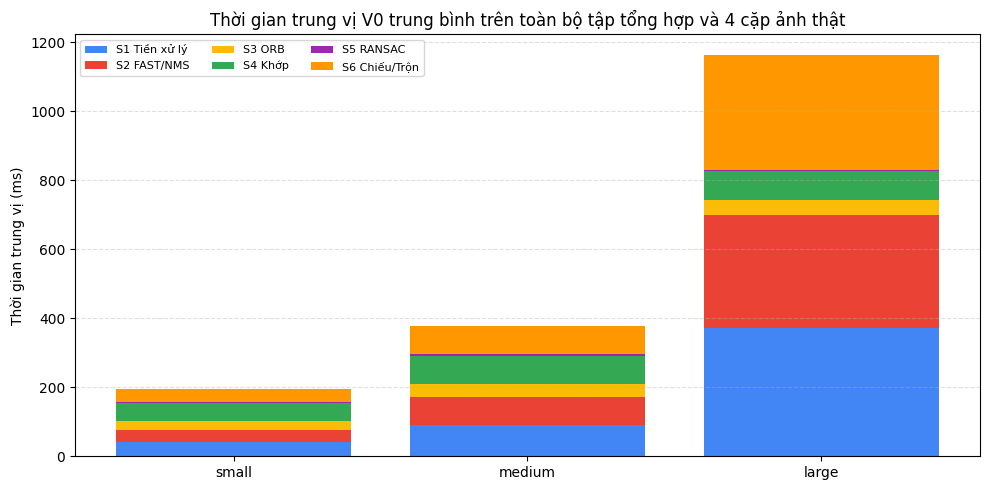

small: Các giai đoạn chiếm ưu thế thời gian là S4 Khớp (51.4 ms), S1 Tiền xử lý (40.1 ms), và S6 Chiếu/Trộn (36.8 ms).
medium: Các giai đoạn chiếm ưu thế thời gian là S1 Tiền xử lý (90.4 ms), S6 Chiếu/Trộn (82.7 ms), và S4 Khớp (82.1 ms).
large: Các giai đoạn chiếm ưu thế thời gian là S1 Tiền xử lý (370.7 ms), S6 Chiếu/Trộn (333.9 ms), và S2 FAST/NMS (330.1 ms).
Ưu tiên tăng tốc GPU là S1 + S2 + S6 vì chi phí của chúng tăng trực tiếp theo số lượng pixel và chiếm áp đảo trong profile đo đạc ở 1080p và 4K. S3-S5 và chi phí host được giữ tuần tự trong mô hình Amdahl bảo thủ này, vì vậy mọi giá trị S_max báo cáo đều là số hữu hạn.


In [13]:
# 6.3 Phân tích giai đoạn thắt nút cổ chai (Hot stages) và Định luật Amdahl hữu hạn
import matplotlib.pyplot as plt
import numpy as np

stage_labels = ["S1 Tiền xử lý", "S2 FAST/NMS", "S3 ORB", "S4 Khớp", "S5 RANSAC", "S6 Chiếu/Trộn"]
stage_keys = [
    "stage1_preprocess", "stage2_fast_nms_topk", "stage3_orb_descriptor",
    "stage4_matching", "stage5_ransac", "stage6_warping_blending",
]
resolutions = ["small", "medium", "large"]
profile_rows = []
mean_by_resolution = {resolution: [] for resolution in resolutions}

for dataset_name in dataset_outputs:
    for resolution in resolutions:
        metrics = json.loads(
            (Path("output") / dataset_name / f"metrics_{resolution}.json").read_text()
        )
        times = np.array([metrics["timing_ms"][key]["median"] for key in stage_keys])
        mean_by_resolution[resolution].append(times)
        hot_index = int(np.argmax(times))
        profile_rows.append({
            "Tập dữ liệu": dataset_name,
            "Độ phân giải": resolution,
            "Giai đoạn thắt nút (Hot stage)": stage_labels[hot_index],
            "Tỷ lệ chiếm (%)": 100.0 * times[hot_index] / metrics["timing_ms"]["end_to_end"]["median"],
            "Amdahl p (S1+S2+S6)": metrics["amdahl_parallel_fraction"],
            "Giới hạn S_max hữu hạn": metrics["amdahl_smax"],
        })

print("Tập dữ liệu | Độ phân giải | Giai đoạn Hot | Chiếm (%) | Amdahl p | S_max hữu hạn")
print("-" * 90)
for row in profile_rows:
    print(
        f"{row['Tập dữ liệu']} | {row['Độ phân giải']} | {row['Giai đoạn thắt nút (Hot stage)']} | "
        f"{row['Tỷ lệ chiếm (%)']:.3f} | {row['Amdahl p (S1+S2+S6)']:.4f} | "
        f"{row['Giới hạn S_max hữu hạn']:.3f}"
    )

means = np.vstack([np.mean(mean_by_resolution[r], axis=0) for r in resolutions])
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(resolutions))
colors = ["#4285F4", "#EA4335", "#FBBC05", "#34A853", "#9C27B0", "#FF9800"]
for index, label in enumerate(stage_labels):
    ax.bar(resolutions, means[:, index], bottom=bottom, label=label, color=colors[index])
    bottom += means[:, index]
ax.set_title("Thời gian trung vị V0 trung bình trên toàn bộ tập tổng hợp và 4 cặp ảnh thật")
ax.set_ylabel("Thời gian trung vị (ms)")
ax.legend(ncol=3, fontsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("output/hot_stage_scaling.png", dpi=150)
plt.show()

for resolution, row in zip(resolutions, means):
    order = np.argsort(row)[::-1]
    print(
        f"{resolution}: Các giai đoạn chiếm ưu thế thời gian là "
        f"{stage_labels[order[0]]} ({row[order[0]]:.1f} ms), "
        f"{stage_labels[order[1]]} ({row[order[1]]:.1f} ms), và "
        f"{stage_labels[order[2]]} ({row[order[2]]:.1f} ms)."
    )
print(
    "Ưu tiên tăng tốc GPU là S1 + S2 + S6 vì chi phí của chúng tăng trực tiếp theo số lượng pixel "
    "và chiếm áp đảo trong profile đo đạc ở 1080p và 4K. S3-S5 và chi phí host được giữ tuần tự "
    "trong mô hình Amdahl bảo thủ này, vì vậy mọi giá trị S_max báo cáo đều là số hữu hạn."
)


In [14]:
# 6.4 Đối chiếu độc lập mô hình biến đổi với OpenCV
homography_report = Path("output/homography_reference.json")
run_checked([
    sys.executable, "scripts/validate_homography.py",
    "--json-out", str(homography_report),
])
reference = json.loads(homography_report.read_text())
print("site | độ phân giải | mô hình V0 | H tham chiếu hợp lệ? | match/inlier tham chiếu | Độ lệch lưới (% đường chéo)")
for row in reference["comparisons"]:
    disagreement = row["v0_reference_grid_disagreement_pct_diagonal"]
    disagreement_text = f"{disagreement:.3f}" if np.isfinite(disagreement) else "N/A"
    print(
        f"{row['site']} | {row['resolution']} | {row.get('v0_transform_model', 'homography')} | "
        f"{row.get('reference_geometrically_plausible', False)} | "
        f"{row['reference_matches']}/{row['reference_inliers']} | "
        f"{disagreement_text}"
    )
print("\nĐộ nhất quán của V0 qua các độ phân giải (Cross-resolution consistency):")
for row in reference["consistency"]:
    print(
        f"{row['site']} | {row['max_cross_resolution_grid_disagreement_pct_diagonal']:.3f}% đường chéo"
    )
print(
    "Diễn giải: Ảnh thật không có ma trận Ground-truth H. OpenCV SIFT + findHomography "
    "chỉ là mốc tham chiếu độc lập. H tham chiếu không qua kiểm tra hình học được báo N/A thay vì "
    "tạo ra một con số lệch lưới gây hiểu nhầm. Khi H projective bị từ chối, V0 chủ động "
    "dùng translation_fallback để tránh canvas suy biến trên texture lặp hoặc cảnh có parallax. "
    "Độ lệch xuyên độ phân giải được đo sau khi chuẩn hóa hệ tọa độ; "
    "độ lệch lớn hơn ở các cảnh ít vân bề mặt cần được phân tích cùng với số lượng inlier "
    "và độ tự nhất quán xuyên độ phân giải của chính V0."
)


site	resolution	V0 model	ref plausible	ref matches/inliers	V0-vs-ref grid disagreement (% diagonal)
site1	small	translation_fallback	False	319/214	N/A
site1	medium	translation_fallback	False	453/298	N/A
site1	large	translation_fallback	False	521/287	N/A
site2	small	translation_fallback	False	328/233	N/A
site2	medium	translation_fallback	False	315/185	N/A
site2	large	translation_fallback	False	353/186	N/A
site3	small	translation_fallback	False	88/34	N/A
site3	medium	translation_fallback	False	64/21	N/A
site3	large	translation_fallback	False	47/0	N/A
challenging	small	translation_fallback	False	316/203	N/A
challenging	medium	translation_fallback	False	385/210	N/A
challenging	large	translation_fallback	False	287/76	N/A

Cross-resolution V0 consistency (normalized coordinates):
site1: 0.217% diagonal
site2: 0.350% diagonal
site3: 1.575% diagonal
challenging: 0.368% diagonal
[OK] Wrote output/homography_reference.json
site | độ phân giải | mô hình V0 | H tham chiếu hợp lệ? | match/inlier th

---
## 7. BỘ SƯU TẬP ẢNH TOÀN CẢNH KẾT QUẢ (VISUAL GALLERY OF STITCHED PANORAMAS)


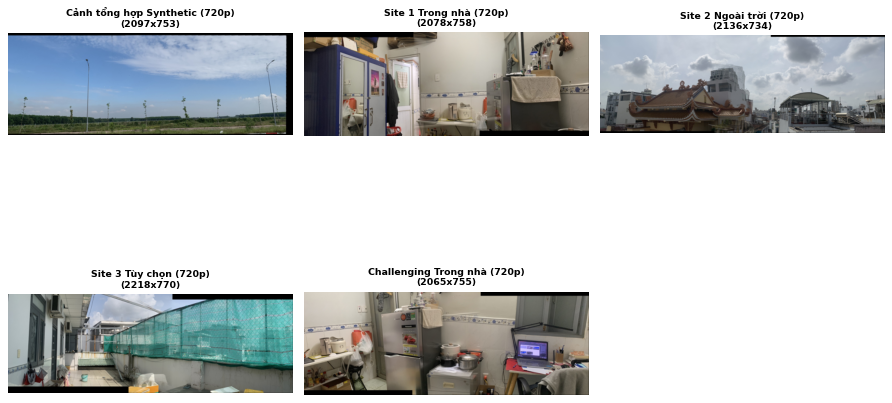

In [15]:
# 7.1 Hiển thị bộ sưu tập ảnh panorama kết quả đã ghép
import os
import matplotlib.pyplot as plt
from PIL import Image

panoramas = [
    ("Cảnh tổng hợp Synthetic (720p)", "output/synthetic/pano_small.jpg"),
    ("Site 1 Trong nhà (720p)", "output/site1/pano_small.jpg"),
    ("Site 2 Ngoài trời (720p)", "output/site2/pano_small.jpg"),
    ("Site 3 Tùy chọn (720p)", "output/site3/pano_small.jpg"),
    ("Challenging Trong nhà (720p)", "output/challenging/pano_small.jpg"),
]

plt.figure(figsize=(12, 8), dpi=75)
idx = 1
for title, p in panoramas:
    if os.path.isfile(p):
        img = Image.open(p)
        preview = img.copy()
        preview.thumbnail((480, 270))
        plt.subplot(2, 3, idx)
        plt.imshow(preview)
        plt.title(f"{title}\n({img.width}x{img.height})", fontsize=9, fontweight='bold')
        plt.axis('off')
        idx += 1

plt.tight_layout()
plt.show()


---
## 8. KẾ HOẠCH TRIỂN KHAI GPU (PHASES C, D, E) (GPU IMPLEMENTATION PLAN)

### 8.1 Lựa chọn dựa trên phân tích đo đạc (Profiling evidence)
Dựa trên bảng và biểu đồ được tính trực tiếp tại Cell 6.3, **S1, S2 và S6 là các mục tiêu tối ưu hóa đầu tiên** vì chi phí của chúng tăng theo số pixel và có mức song song dữ liệu cao. Tỷ lệ thực tế, hot stage và giới hạn Amdahl cho từng dataset/độ phân giải được in từ các tệp metrics ngay phía trên, không hard-code trong phần diễn giải.  
Phiên bản V1 sẽ chuyển toàn bộ cả 6 giai đoạn lên GPU để dữ liệu trung gian luôn thường trú trên bộ nhớ thiết bị; mô hình Amdahl bảo thủ tập trung tăng tốc S1/S2/S6 và giữ S3-S5 cùng chi phí truyền nhận ở dạng tuần tự.

### 8.2 Bảng phân bố luồng V1 (V1 Thread Mapping)

| Giai đoạn | Cơ chế ánh xạ luồng CUDA | Rủi ro tính đúng đắn và giải pháp khắc phục |
|---|---|---|
| **S1 (Mức xám + Lọc mờ)** | Khối 2D $16\times 16$, 1 thread tính 1 pixel đầu ra | Lỗi vùng đệm halo/biên; kiểm tra đối chiếu từng chính sách biên clamp với V0 |
| **S2 (FAST + NMS + Top-K)** | Detector/NMS dạng 2D, thu gọn bounded compaction, khóa sắp xếp tất định | Tràn bộ đệm ứng viên và thứ tự atomic không tất định; cấp phát đúng dung lượng và tie-break ổn định |
| **S3 (Mô tả ORB)** | 1 thread xử lý 1 keypoint, bảng mẫu lưu trong `__constant__` memory | Vùng patch xoay vượt ngoài biên ảnh; tái sử dụng điều kiện biên an toàn của V0 |
| **S4 (Khớp đặc trưng)** | Phân khối tile 2D descriptor, chỉ thị phần cứng popcount, reduction tìm 2 điểm gần nhất | Sai lệch điểm nhì hoặc xử lý bằng điểm; kiểm thử hồi quy đối chiếu chính xác với matches của V0 |
| **S5 (RANSAC DLT/fallback)** | 1 thread hoặc warp xử lý 1 giả thuyết; fallback displacement dùng reduction/histogram robust | Mẫu suy biến, texture lặp và reduction không tất định; kiểm tra hình học, seed/tie-break cố định và đối chiếu model flag với V0 |
| **S6 (Chiếu & Trộn)** | Lưới 2D canvas, ánh xạ tọa độ ngược, lấy mẫu texture/bilinear | Canvas/alpha không hợp lệ và trôi dạt nội suy; xác thực biên trên host và kiểm tra dung sai pixel |

### 8.3 Các ý tưởng tối ưu hóa ứng viên (Một ý tưởng cốt lõi cho mỗi phiên bản)

1. **Phân khối bộ nhớ chia sẻ (Shared-Memory Tiling) cho S1 blur:** Tái sử dụng vùng lân cận $5\times 5$. Rủi ro: lưu lượng truyền vùng đệm halo, xung đột bank bộ nhớ và giảm occupancy có thể triệt tiêu hiệu năng.
2. **Thu gọn 2-pass compaction kèm sắp xếp GPU tất định cho S2:** Loại bỏ bước gom ứng viên tuần tự trên CPU. Rủi ro: tốn thêm bộ nhớ tạm và chi phí sắp xếp tăng ở ảnh nhỏ 720p.
3. **Lấy mẫu Texture-object phần cứng cho S6:** Tận dụng bộ đệm đọc 2D cache và nội suy phần cứng tích hợp của GPU. Rủi ro: sự khác biệt về làm tròn tọa độ so với CPU có thể vượt ngưỡng dung sai ảnh panorama.

Quyết định chọn tối ưu V2 sẽ dựa trên bằng chứng đo đạc Nsight Compute sau khi hoàn thành V1; V3 chỉ được lựa chọn sau khi profile lại V2. Chi phí truyền dữ liệu H2D/D2H, thiết lập, và thời gian kernel luôn được đo tách biệt để không che giấu chi phí giao tiếp.


---
## 9. MÃ NGUỒN BÊN THỨ BA, TÀI LIỆU THAM KHẢO & TUYÊN BỐ AI (THIRD-PARTY SOURCES, REFERENCES & AI DISCLOSURE)

- Bảng mẫu tọa độ OpenCV `bit_pattern_31_`, giấy phép BSD-3-Clause:  
  https://github.com/opencv/opencv/blob/4.x/modules/features2d/src/orb.cpp
- Thư viện đọc/ghi ảnh stb_image và stb_image_write, Public Domain / MIT:  
  https://github.com/nothings/stb
- Rosten & Drummond, Thuật toán phát hiện FAST, ECCV 2006:  
  https://doi.org/10.1007/11744023_34
- Rublee et al., Thuật toán mô tả đặc trưng ORB, ICCV 2011:  
  https://doi.org/10.1109/ICCV.2011.6126544
- Lowe, Phương pháp kiểm định tỷ số so khớp (Ratio test), IJCV 2004:  
  https://doi.org/10.1023/B:VISI.0000029664.99615.94
- Fischler & Bolles, Thuật toán RANSAC, CACM 1981:  
  https://doi.org/10.1145/358669.358692
- Hartley & Zisserman, *Multiple View Geometry in Computer Vision*, Tái bản lần 2, NXB Đại học Cambridge, 2004.

Mã nguồn/dữ liệu sao chép từ bên ngoài được giới hạn ở bảng tọa độ ORB của OpenCV và hai file tiêu đề nguyên bản của stb; chi tiết giấy phép được lưu tại `THIRD_PARTY_NOTICES.md`.  
Trí tuệ nhân tạo (Generative AI) được sử dụng để hỗ trợ rà soát mã nguồn, gợi ý danh mục kiểm tra kiểm thử và hiệu đính văn phong tài liệu. Các thành viên trong nhóm trực tiếp kiểm tra từng thay đổi, tự chạy kiểm thử/benchmark và hoàn toàn chịu trách nhiệm cho mọi kết quả nộp bài cũng như phần thuyết minh vấn đáp.
